R0 = 4.408043839436389
U0 = 161923.75408660917
sigma_R = 0.004728708045015879
omega_breath = 2.23606797749979
E0 = 161924.87212059792
E1 = 161927.10818857542


/tmp/ipykernel_1814/3070215777.py:355: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


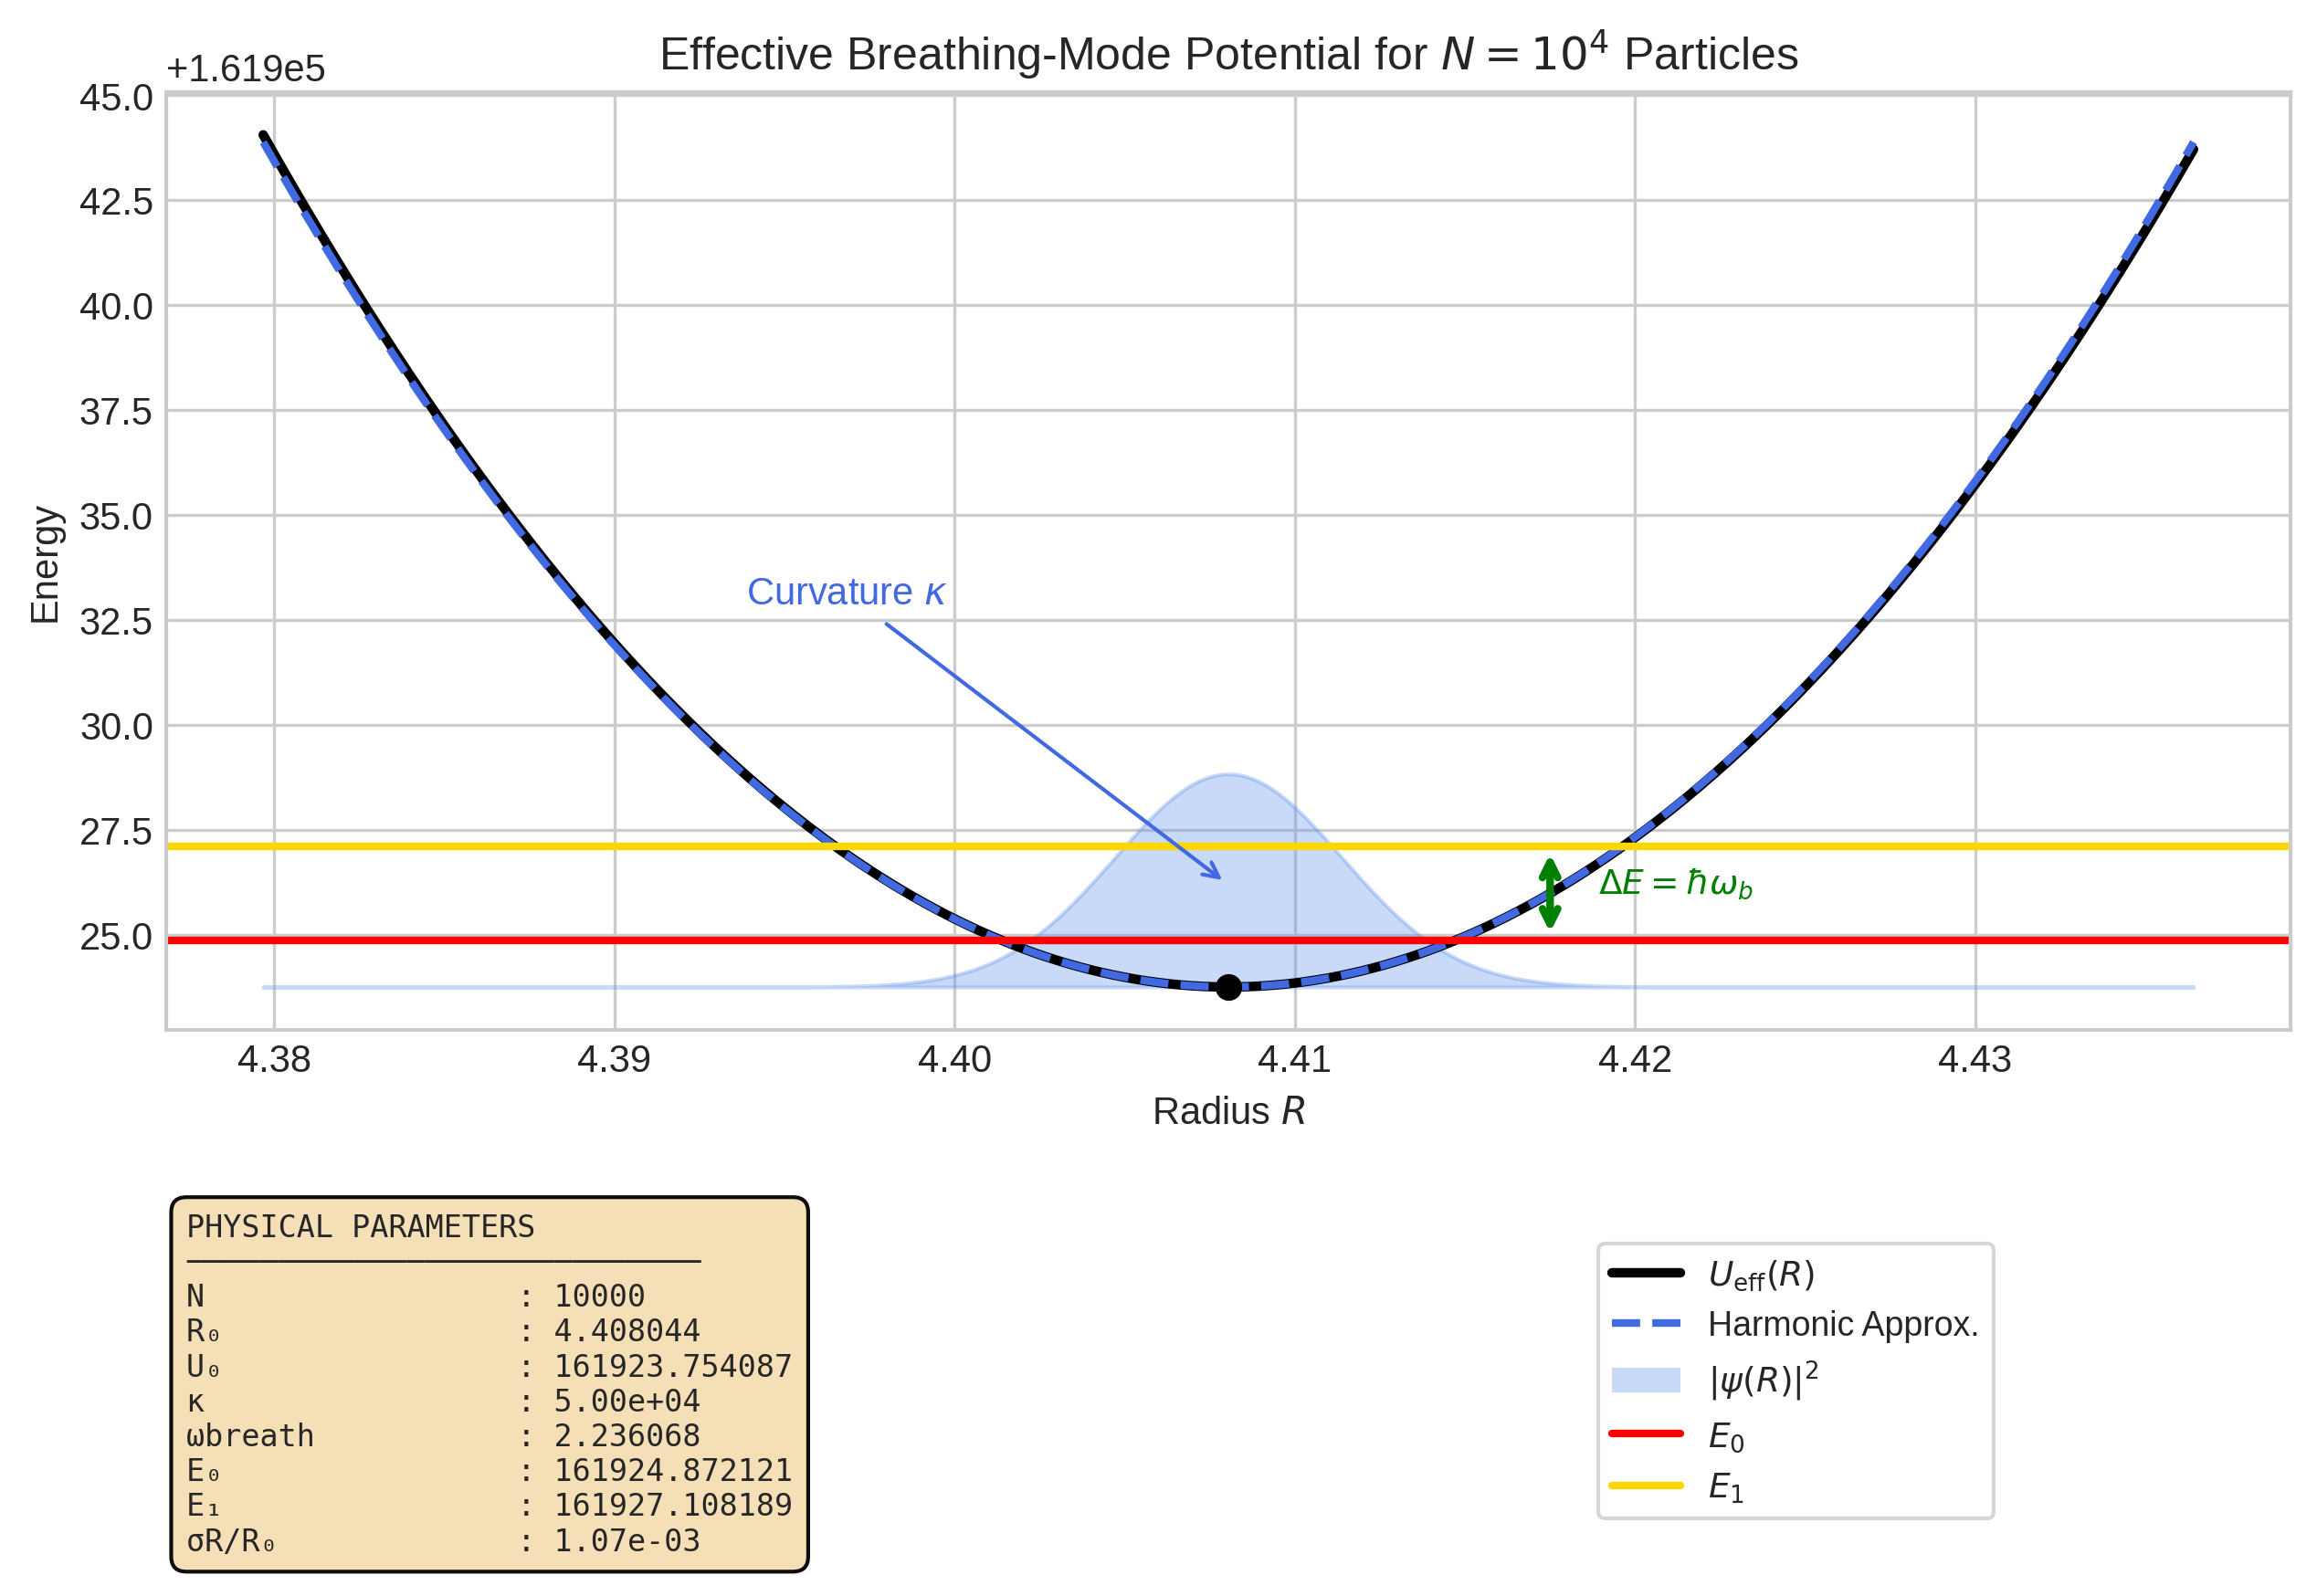

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

N = 10000
omega_eff = 1.0
g = 1.0
m = 1.0
hbar = 1.0

A = 0.5 * N * m * omega_eff**2

B = (3 * g / (8 * np.pi)) * (3/5)**(3/2) * N**2

R0 = ((3 * B) / (2 * A))**(1/5)

U0 = A * R0**2 + B / R0**3

kappa = 5 * N * m * omega_eff**2

omega_breath = np.sqrt(5) * omega_eff

M_R = N * m

sigma_R = np.sqrt(
    hbar /
    (2 * M_R * omega_breath)
)

E0 = U0 + 0.5 * hbar * omega_breath

E1 = U0 + 1.5 * hbar * omega_breath

print(f"R0 = {R0}")
print(f"U0 = {U0}")
print(f"sigma_R = {sigma_R}")
print(f"omega_breath = {omega_breath}")
print(f"E0 = {E0}")
print(f"E1 = {E1}")

R = np.linspace(
    R0 - 6*sigma_R,
    R0 + 6*sigma_R,
    1200
)

U = A * R**2 + B / R**3

Uh = (
    U0
    +
    0.5 * kappa * (R - R0)**2
)

u = (R - R0) / sigma_R

psi = (
    (1/np.pi)**0.25
    *
    np.exp(-u**2/2)
)

prob = psi**2

prob /= np.max(prob)

scale = 0.25 * (np.max(U) - np.min(U))

prob_scaled = U0 + scale * prob

plt.style.use("seaborn-v0_8-whitegrid")

fig = plt.figure(
    figsize=(10,7),
    dpi=300
)

gs = GridSpec(
    2,
    2,
    height_ratios=[4,1.6],
    hspace=0.25,
    wspace=0.15
)

ax = fig.add_subplot(gs[0,:])

ax_param = fig.add_subplot(gs[1,0])
ax_legend = fig.add_subplot(gs[1,1])

ax_param.axis('off')
ax_legend.axis('off')


ax.plot(
    R,
    U,
    color="black",
    lw=2.5
)

ax.plot(
    R,
    Uh,
    "--",
    color="royalblue",
    lw=2
)

ax.fill_between(
    R,
    U0,
    prob_scaled,
    color="cornflowerblue",
    alpha=0.35
)

ax.axhline(
    E0,
    color="red",
    lw=2
)

ax.axhline(
    E1,
    color="gold",
    lw=2
)

ax.scatter(
    R0,
    U0,
    color="black",
    zorder=10
)

xgap = R0 + 2*sigma_R

ax.annotate(
    "",
    xy=(xgap,E1),
    xytext=(xgap,E0),
    arrowprops=dict(
        arrowstyle="<->",
        color="green",
        lw=2
    )
)

ax.text(
    xgap + 0.3*sigma_R,
    (E0+E1)/2,
    r"$\Delta E=\hbar\omega_b$",
    color="green",
    fontsize=9
)

ax.annotate(
    r"Curvature $\kappa$",
    xy=(
        R0,
        U0 + 0.12*(np.max(U)-U0)
    ),
    xytext=(
        R0 - 3*sigma_R,
        U0 + 0.45*(np.max(U)-U0)
    ),
    arrowprops=dict(
        arrowstyle="->",
        color="royalblue"
    ),
    color="royalblue"
)

ax.set_xlabel(
    r"Radius $R$"
)

ax.set_ylabel(
    "Energy"
)

ax.set_title(
    r"Effective Breathing-Mode Potential for $N=10^4$ Particles"
)

param_text = (
    "PHYSICAL PARAMETERS\n"
    "────────────────────────────\n"
    f"N                 : {N}\n"
    f"R₀                : {R0:.6f}\n"
    f"U₀                : {U0:.6f}\n"
    f"κ                 : {kappa:.2e}\n"
    f"ωbreath           : {omega_breath:.6f}\n"
    f"E₀                : {E0:.6f}\n"
    f"E₁                : {E1:.6f}\n"
    f"σR/R₀             : {sigma_R/R0:.2e}"
)

ax_param.text(
    0.02,
    0.95,
    param_text,
    fontsize=8,
    family='monospace',
    va='top',
    bbox=dict(
        boxstyle='round,pad=0.5',
        facecolor='wheat',
        edgecolor='black',
        alpha=0.95
    )
)

legend_handles = [

    Line2D(
        [0],[0],
        color='black',
        lw=2.5,
        label=r'$U_{\rm eff}(R)$'
    ),

    Line2D(
        [0],[0],
        color='royalblue',
        lw=2,
        linestyle='--',
        label='Harmonic Approx.'
    ),

    Patch(
        facecolor='cornflowerblue',
        alpha=0.35,
        label=r'$|\psi(R)|^2$'
    ),

    Line2D(
        [0],[0],
        color='red',
        lw=2,
        label=r'$E_0$'
    ),

    Line2D(
        [0],[0],
        color='gold',
        lw=2,
        label=r'$E_1$'
    )
]

ax_legend.legend(
    handles=legend_handles,
    loc='center',
    fontsize=9,
    frameon=True
)

ax_legend.axis('off')

plt.savefig(
    "Fig1_EffectivePotential_N10000.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Fig1_EffectivePotential_N10000.pdf",
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()

Epoch     0 E=5.22280216
Epoch   500 E=1.11803520
Epoch  1000 E=1.11803448
Epoch  1500 E=1.11803150
Epoch  2000 E=1.11803389
Epoch  2500 E=1.11803401
Epoch  3000 E=1.11803353
Epoch  3500 E=1.11803377
Epoch  4000 E=1.11803389
Epoch  4500 E=1.11803496
Epoch  5000 E=1.11797941
Epoch  5500 E=1.11803377
Epoch  6000 E=1.11804605
Epoch  6500 E=1.11802721
Epoch  7000 E=1.11803401
Epoch  7500 E=1.11803305
Epoch  8000 E=1.11823475
Epoch  8500 E=1.11802888
Epoch  9000 E=1.48093426
Epoch  9500 E=1.11803257
Epoch 10000 E=1.11803401
Epoch 10500 E=1.11803401
Epoch 11000 E=1.11803401
Epoch 11500 E=1.11803401
Epoch 12000 E=1.11803401
Epoch 12500 E=1.11803401
Epoch 13000 E=1.11803401
Epoch 13500 E=1.11803401
Epoch 14000 E=1.11803401
Epoch 14500 E=1.11803401
Epoch 15000 E=1.11803401
Epoch 15500 E=1.11803401
Epoch 16000 E=1.11803401
Epoch 16500 E=1.11803401
Epoch 17000 E=1.11803401
Epoch 17500 E=1.11803401
Epoch 18000 E=1.11803401
Epoch 18500 E=1.11803401
Epoch 19000 E=1.11803401
Epoch 19500 E=1.11803401


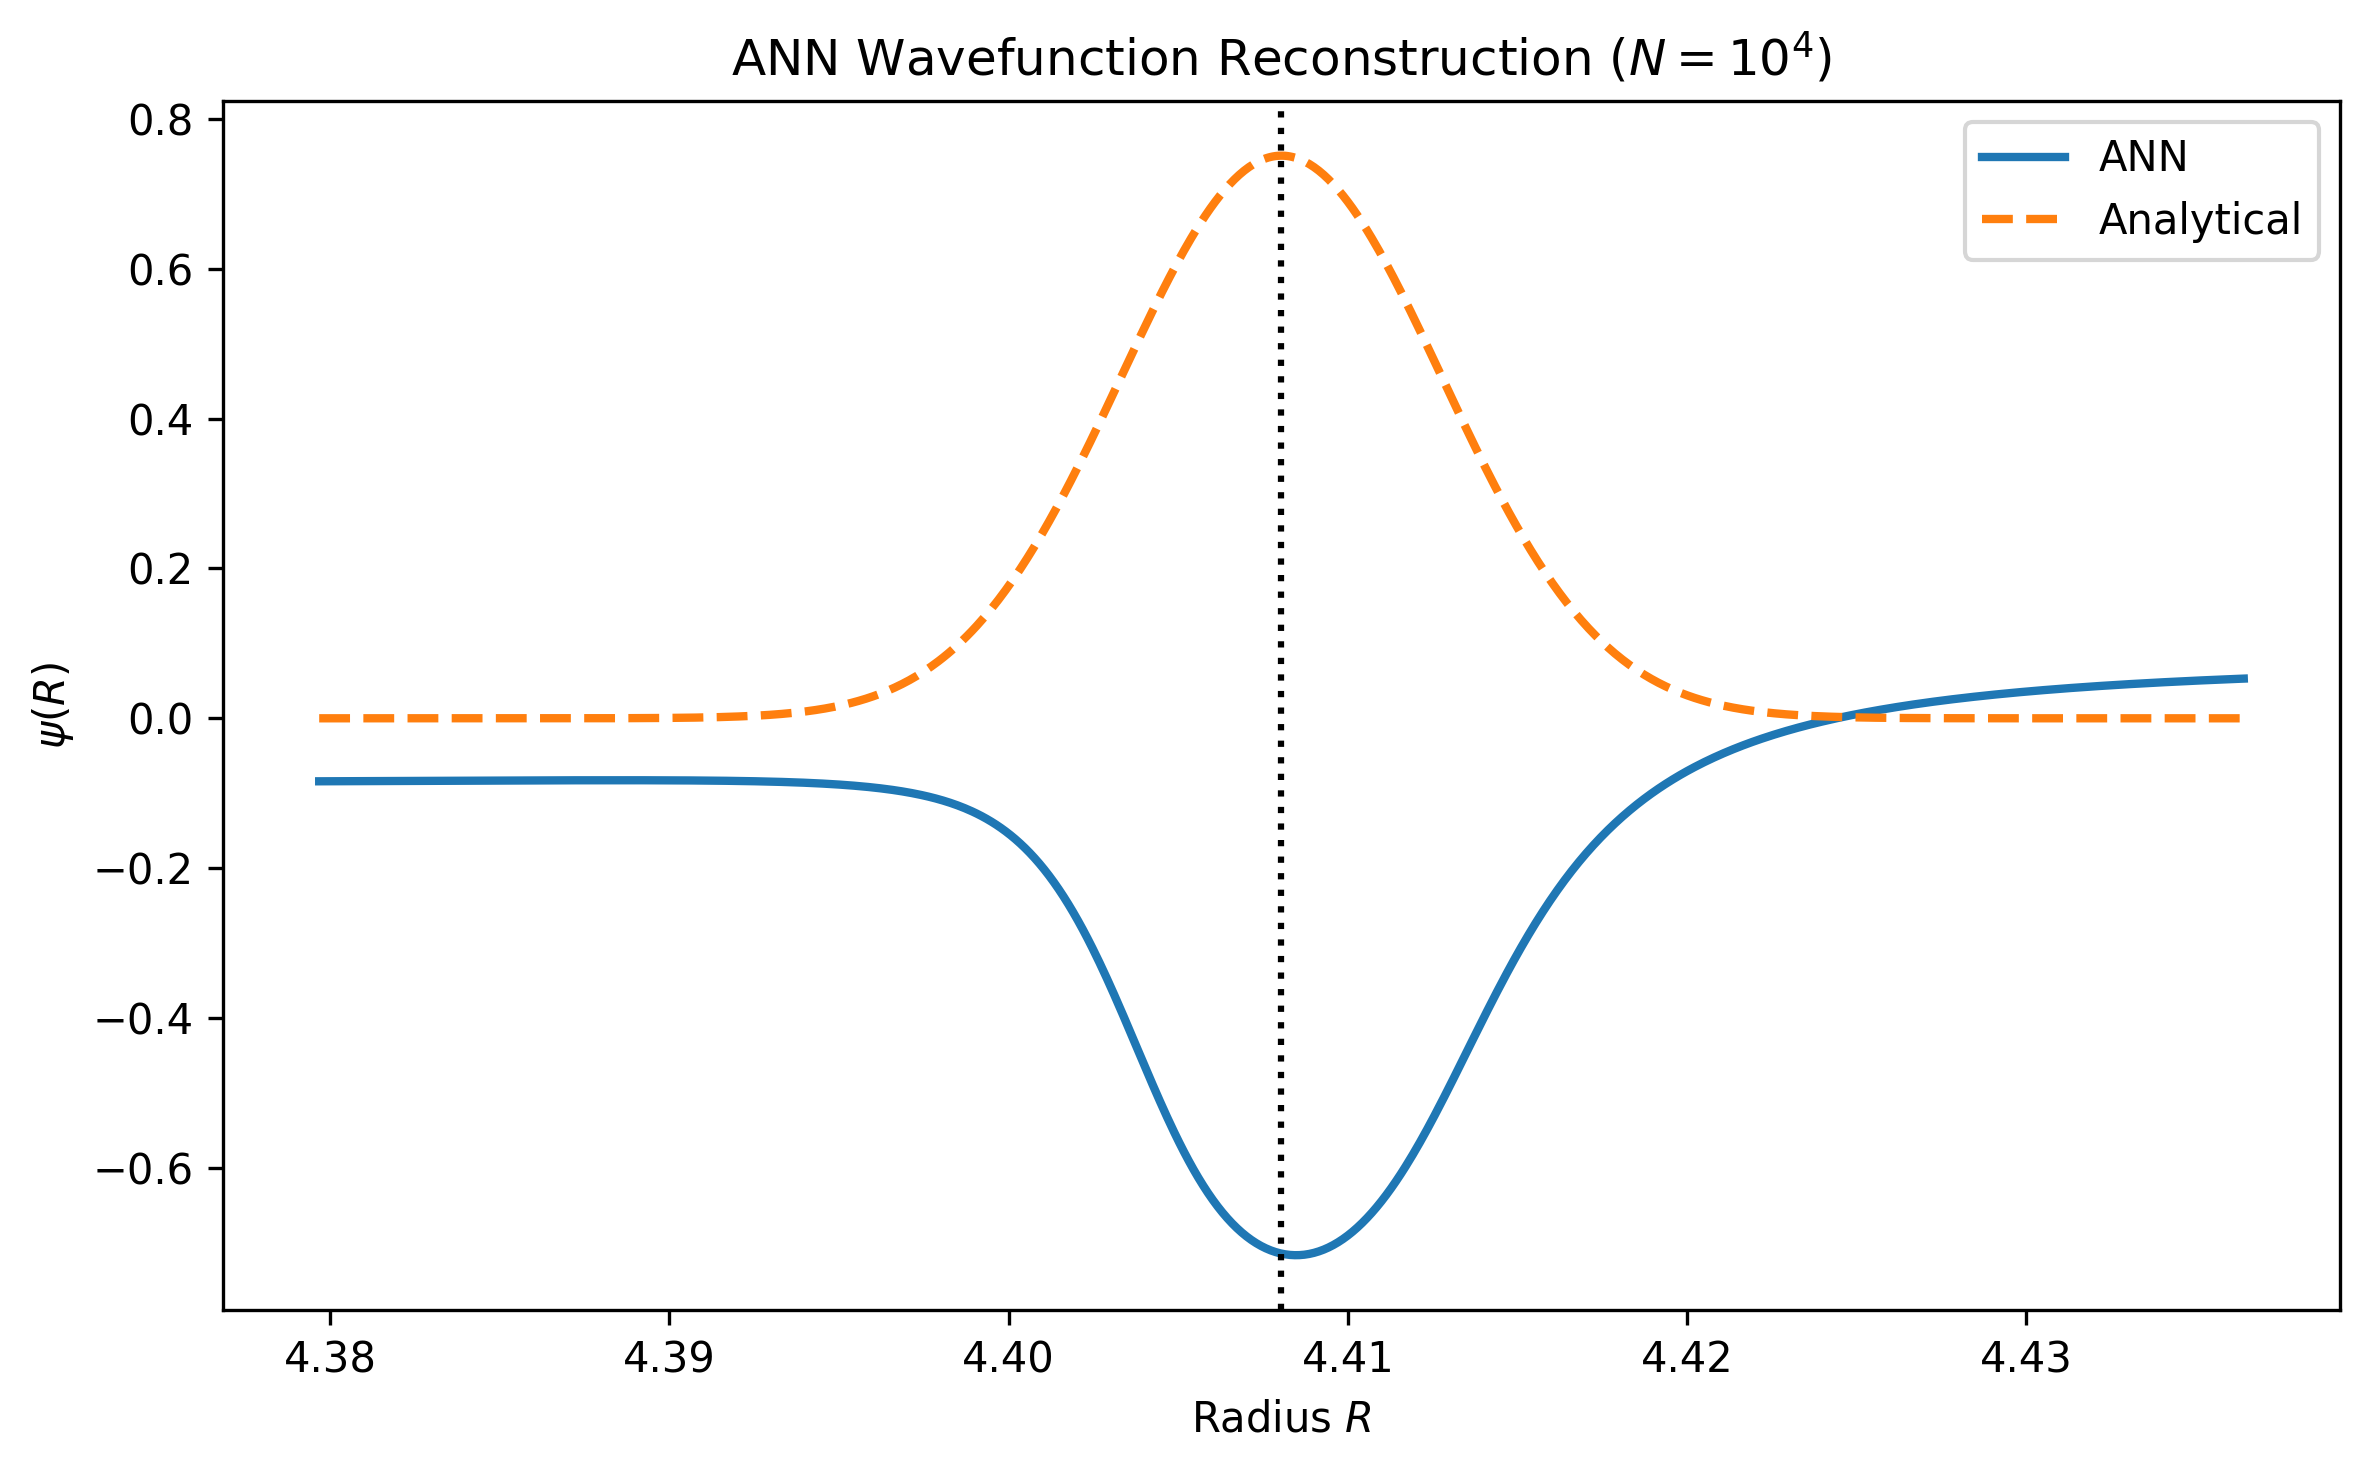

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

class PhysicalSystem:

    def __init__(self,
                 N=10000,
                 omega_eff=1.0,
                 g=1.0,
                 m=1.0):

        self.N = N
        self.omega_eff = omega_eff
        self.g = g
        self.m = m
        self.hbar = 1.0

        self.A = 0.5*N*m*omega_eff**2

        self.B = (
            3*g/(8*np.pi)
        )*(3/5)**(3/2)*N**2

        self.R0 = (
            (3*self.B)/(2*self.A)
        )**(1/5)

        self.U0 = (
            self.A*self.R0**2
            +
            self.B/self.R0**3
        )

        self.kappa = 5*N*m*omega_eff**2

        self.M_R = N*m

        self.omega_breath = np.sqrt(5)*omega_eff

        self.sigma_R = np.sqrt(
            self.hbar/
            (
                2*self.M_R*self.omega_breath
            )
        )


class WavefunctionNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(1,128),
            nn.Tanh(),

            nn.Linear(128,128),
            nn.Tanh(),

            nn.Linear(128,128),
            nn.Tanh(),

            nn.Linear(128,1)

        )

    def forward(self,x):

        return self.net(x)


class Solver:

    def __init__(self,phys):

        self.phys = phys

        self.u = np.linspace(-6,6,800)

        self.du = self.u[1]-self.u[0]

        self.R = (
            phys.R0
            +
            phys.sigma_R*self.u
        )

        self.u_tensor = torch.tensor(
            self.u,
            dtype=torch.float32
        ).reshape(-1,1)

        self.model = WavefunctionNN()

        self.optimizer = optim.Adam(
            self.model.parameters(),
            lr=1e-3
        )
        self.scheduler = optim.lr_scheduler.StepLR(
            self.optimizer,
            step_size=10000,
            gamma=0.1
        )

        self.energy_history = []


    def energy(self,psi):

        psi = psi.flatten()

        norm = torch.trapezoid(
            psi*psi,
            dx=self.du
        )

        psi = psi/torch.sqrt(norm)

        psi_uu = torch.zeros_like(psi)

        psi_uu[1:-1] = (
            psi[2:]
            -
            2*psi[1:-1]
            +
            psi[:-2]
        )/(self.du**2)

        T = (
            -0.5
            *
            self.phys.hbar
            *
            self.phys.omega_breath
            *
            psi_uu
            *
            psi
        )

        V = (
            0.5
            *
            self.phys.kappa
            *
            self.phys.sigma_R**2
            *
            self.u_tensor.flatten()**2
            *
            psi**2
        )

        E = torch.trapezoid(
            T+V,
            dx=self.du
        )
        return E, norm

    def train(self,epochs=20000):

        target = (
            0.5
            *
            self.phys.hbar
            *
            self.phys.omega_breath
        )

        for epoch in range(epochs):

            self.optimizer.zero_grad()

            psi = self.model(
                self.u_tensor
            )

            E, norm = self.energy(psi)

            loss = (
                 (E-target)**2
                  +
                  10*(norm-1.0)**2
            )

            loss.backward()

            self.optimizer.step()

            self.scheduler.step()

            self.energy_history.append(
                E.item()
            )

            if epoch%500==0:

                print(
                    f"Epoch {epoch:5d} "
                    f"E={E.item():.8f}"
                )

        with torch.no_grad():

            psi = self.model(
                self.u_tensor
            ).flatten().numpy()

            norm = np.trapezoid(
                psi**2,
                dx=self.du
            )

            self.psi_nn = psi/np.sqrt(norm)

phys = PhysicalSystem(
    N=10000
)

solver = Solver(phys)

solver.train()

psi_analytic = (
    (1/np.pi)**0.25
    *
    np.exp(-solver.u**2/2)
)

overlap = np.abs(
    np.trapezoid(
        solver.psi_nn
        *
        psi_analytic,
        dx=solver.du
    )
)

print()
print("Overlap =", overlap)

plt.figure(
    figsize=(8,5),
    dpi=300
)

plt.plot(
    solver.R,
    solver.psi_nn,
    lw=2,
    label="ANN"
)

plt.plot(
    solver.R,
    psi_analytic,
    "--",
    lw=2,
    label="Analytical"
)

plt.axvline(
    phys.R0,
    color='black',
    linestyle=':'
)

plt.xlabel(
    r"Radius $R$"
)

plt.ylabel(
    r"$\psi(R)$"
)

plt.title(
    r"ANN Wavefunction Reconstruction ($N=10^4$)"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "Fig2_Wavefunction_Reconstruction.png",
    dpi=600,
    bbox_inches='tight'
)

plt.show()

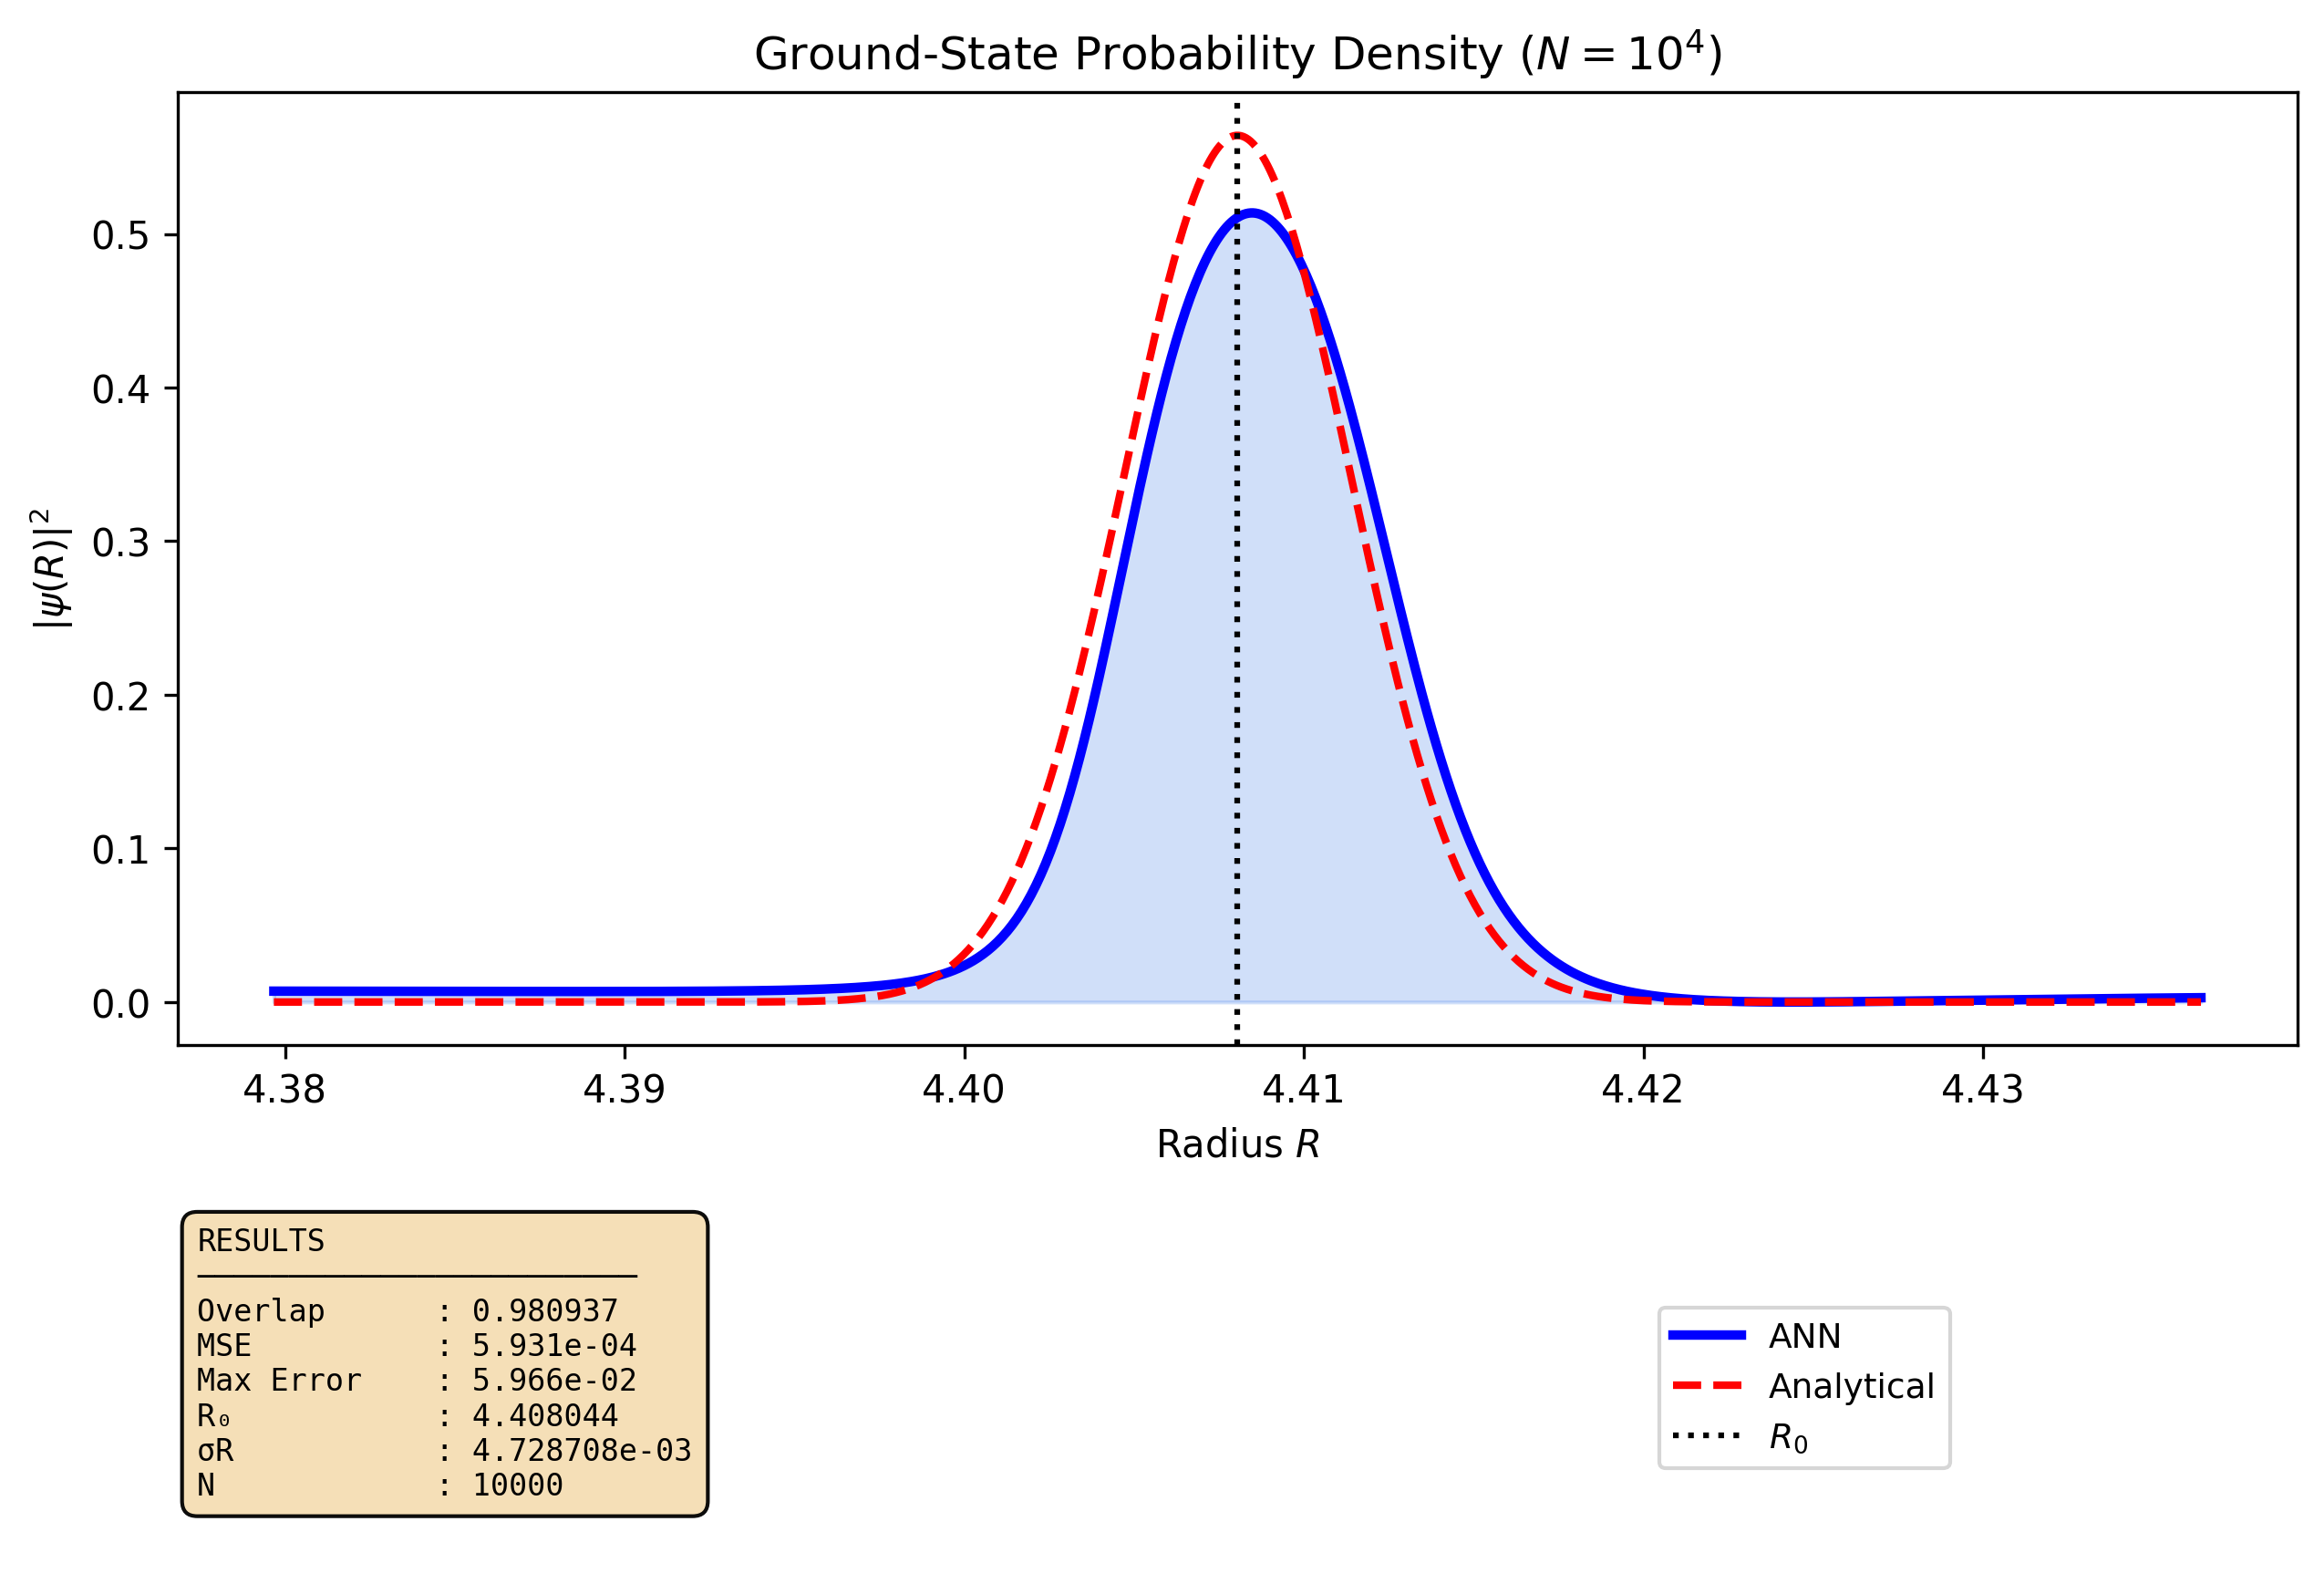

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

psi_analytic = (
    (1/np.pi)**0.25
    *
    np.exp(-solver.u**2/2)
)

rho_nn = solver.psi_nn**2

rho_analytic = psi_analytic**2

mse = np.mean(
    (rho_nn-rho_analytic)**2
)

max_error = np.max(
    np.abs(
        rho_nn-rho_analytic
    )
)

fig = plt.figure(
    figsize=(10,7),
    dpi=300
)

from matplotlib.gridspec import GridSpec

gs = GridSpec(
    2,
    2,
    height_ratios=[4,1.5],
    hspace=0.25,
    wspace=0.15
)

ax = fig.add_subplot(gs[0,:])

ax_param = fig.add_subplot(gs[1,0])

ax_legend = fig.add_subplot(gs[1,1])

ax_param.axis("off")
ax_legend.axis("off")

ax.plot(
    solver.R,
    rho_nn,
    color="blue",
    lw=2.5
)

ax.plot(
    solver.R,
    rho_analytic,
    "--",
    color="red",
    lw=2
)

ax.fill_between(
    solver.R,
    0,
    rho_nn,
    color="cornflowerblue",
    alpha=0.30
)

ax.axvline(
    phys.R0,
    color="black",
    linestyle=":",
    lw=1.5
)

ax.set_xlabel(
    r"Radius $R$"
)

ax.set_ylabel(
    r"$|\psi(R)|^2$"
)

ax.set_title(
    r"Ground-State Probability Density ($N=10^4$)"
)

param_text = (
    "RESULTS\n"
    "────────────────────────\n"
    f"Overlap      : {overlap:.6f}\n"
    f"MSE          : {mse:.3e}\n"
    f"Max Error    : {max_error:.3e}\n"
    f"R₀           : {phys.R0:.6f}\n"
    f"σR           : {phys.sigma_R:.6e}\n"
    f"N            : {phys.N}"
)

ax_param.text(
    0.02,
    0.95,
    param_text,
    fontsize=8,
    family='monospace',
    va='top',
    bbox=dict(
        boxstyle='round,pad=0.5',
        facecolor='wheat',
        edgecolor='black',
        alpha=0.95
    )
)

legend_handles = [

    Line2D(
        [0],[0],
        color='blue',
        lw=2.5,
        label='ANN'
    ),

    Line2D(
        [0],[0],
        color='red',
        linestyle='--',
        lw=2,
        label='Analytical'
    ),

    Line2D(
        [0],[0],
        color='black',
        linestyle=':',
        lw=1.5,
        label=r'$R_0$'
    )

]

ax_legend.legend(
    handles=legend_handles,
    loc='center',
    fontsize=9,
    frameon=True
)

fig.savefig(
    "Fig3_ProbabilityDensity_N10000.png",
    dpi=600,
    bbox_inches='tight'
)

fig.savefig(
    "Fig3_ProbabilityDensity_N10000.pdf",
    bbox_inches='tight'
)

plt.show()

NEURAL NETWORK SOLUTION FOR BREATHING MODE

Physical System:
  R0 = 1.1073
  U0 = 10.2167
  σ_R = 0.1495
  ω_breath = 2.2361
  ħω_breath/2 = 1.1180
  Total E0 = U0 + ħω_breath/2 = 11.3347

Training...
------------------------------------------------------------
Epoch    0: Energy = 3.955167 (target: 1.118034), Loss = 6.612065, Norm = 0.868619
Epoch  500: Energy = 1.120726 (target: 1.118034), Loss = 0.001241, Norm = 0.988885
Epoch 1000: Energy = 1.118033 (target: 1.118034), Loss = 0.000000, Norm = 1.000002
Epoch 1500: Energy = 1.119734 (target: 1.118034), Loss = 0.000308, Norm = 0.994473
Epoch 2000: Energy = 1.110402 (target: 1.118034), Loss = 0.013856, Norm = 1.037160
Epoch 2500: Energy = 1.118033 (target: 1.118034), Loss = 0.000000, Norm = 0.999999
Epoch 3000: Energy = 1.118418 (target: 1.118034), Loss = 0.000030, Norm = 0.998277
Epoch 3500: Energy = 1.120056 (target: 1.118034), Loss = 0.000340, Norm = 0.994194
Epoch 4000: Energy = 1.118563 (target: 1.118034), Loss = 0.000017, Norm = 

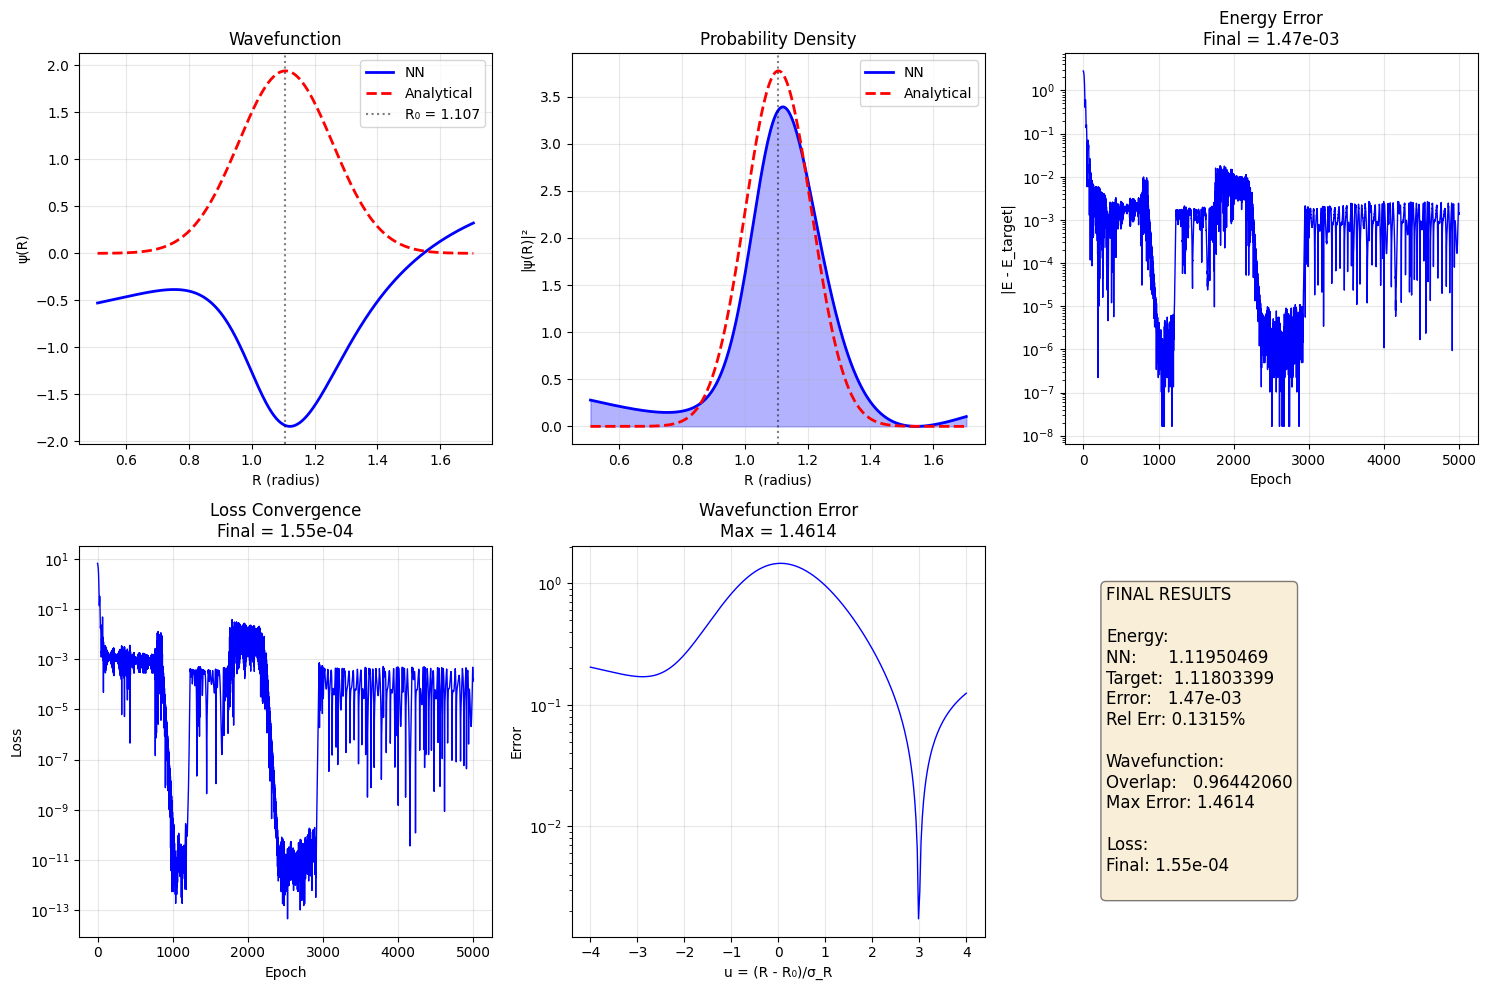

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

class PhysicalSystem:
    def __init__(self, N=10, omega_eff=1.0, g=1.0, m=1.0):
        self.N = N
        self.omega_eff = omega_eff
        self.g = g
        self.m = m
        self.hbar = 1.0


        self.A = 0.5 * self.N * self.m * self.omega_eff**2
        self.B = (3 * self.g / (8 * np.pi)) * (3/5)**(3/2) * self.N**2
        self.R0 = ((3 * self.B) / (2 * self.A))**(1/5)


        self.U0 = self.A * self.R0**2 + self.B / self.R0**3


        self.M_R = self.N * self.m
        self.omega_breath = np.sqrt(5) * self.omega_eff
        self.kappa = 5 * self.N * self.m * self.omega_eff**2
        self.sigma_R = np.sqrt(self.hbar / (2 * self.M_R * self.omega_breath))

        print(f"\nPhysical System:")
        print(f"  R0 = {self.R0:.4f}")
        print(f"  U0 = {self.U0:.4f}")
        print(f"  σ_R = {self.sigma_R:.4f}")
        print(f"  ω_breath = {self.omega_breath:.4f}")
        print(f"  ħω_breath/2 = {0.5 * self.hbar * self.omega_breath:.4f}")
        print(f"  Total E0 = U0 + ħω_breath/2 = {self.U0 + 0.5 * self.hbar * self.omega_breath:.4f}")

class WavefunctionNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)

class Solver:
    def __init__(self, phys):
        self.phys = phys


        self.u_min = -4.0
        self.u_max = 4.0
        self.n_points = 300
        self.u = np.linspace(self.u_min, self.u_max, self.n_points)
        self.du = self.u[1] - self.u[0]

        self.R = self.phys.R0 + self.phys.sigma_R * self.u

        self.u_tensor = torch.tensor(self.u, dtype=torch.float32).reshape(-1, 1)
        self.u_tensor.requires_grad_(True)

        self.model = WavefunctionNN()
        self.optimizer = optim.Adam(self.model.parameters(), lr=0.001)


        self.energy_history = []
        self.loss_history = []

    def compute_energy(self, psi, u):

        psi = psi.flatten()
        u = u.flatten()


        norm = torch.trapezoid(psi * psi, dx=self.du)

        if norm < 1e-10:
            return torch.tensor(100.0, requires_grad=True)


        psi_norm = psi / torch.sqrt(norm)


        psi_u = torch.zeros_like(psi_norm)
        psi_u[1:-1] = (psi_norm[2:] - psi_norm[:-2]) / (2 * self.du)
        psi_u[0] = (psi_norm[1] - psi_norm[0]) / self.du
        psi_u[-1] = (psi_norm[-1] - psi_norm[-2]) / self.du


        psi_uu = torch.zeros_like(psi_norm)
        psi_uu[1:-1] = (psi_norm[2:] - 2*psi_norm[1:-1] + psi_norm[:-2]) / (self.du**2)
        psi_uu[0] = psi_uu[1]
        psi_uu[-1] = psi_uu[-2]


        T_density = -0.5 * self.phys.hbar * self.phys.omega_breath * psi_uu * psi_norm

        V_density = 0.5 * self.phys.kappa * self.phys.sigma_R**2 * u**2 * psi_norm * psi_norm

        H_density = T_density + V_density

        E_breath = torch.trapezoid(H_density, dx=self.du)

        return E_breath, norm

    def train_step(self):
        self.optimizer.zero_grad()

        psi = self.model(self.u_tensor).flatten()

        E_breath, norm = self.compute_energy(psi, self.u_tensor)

        target = 0.5 * self.phys.hbar * self.phys.omega_breath


        energy_loss = (E_breath - target)**2 / (target**2 + 1e-8)
        norm_loss = (norm - 1.0)**2


        loss = energy_loss + 10.0 * norm_loss


        loss.backward()


        torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)

        self.optimizer.step()

        return loss.item(), E_breath.item(), norm.item()

    def train(self, n_epochs=5000):
        print("\nTraining...")
        print("-" * 60)

        target = 0.5 * self.phys.hbar * self.phys.omega_breath

        for epoch in range(n_epochs):
            loss, energy, norm = self.train_step()

            self.energy_history.append(energy)
            self.loss_history.append(loss)

            if epoch % 500 == 0:
                print(f"Epoch {epoch:4d}: Energy = {energy:.6f} (target: {target:.6f}), Loss = {loss:.6f}, Norm = {norm:.6f}")

        with torch.no_grad():
            psi_final = self.model(self.u_tensor).flatten().numpy()


        norm = np.trapezoid(psi_final**2, dx=self.du)
        self.psi_final = psi_final / np.sqrt(norm)
        self.E_final = energy

        print(f"\nFinal Results:")
        print(f"  Energy: {self.E_final:.8f} (target: {target:.8f})")
        print(f"  Error: {abs(self.E_final - target):.2e}")
        print(f"  Relative error: {abs(self.E_final - target)/target*100:.4f}%")

    def plot(self):

        psi_analytical = (1/np.pi)**(0.25) * np.exp(-self.u**2/2)
        target = 0.5 * self.phys.hbar * self.phys.omega_breath

        fig, axes = plt.subplots(2, 3, figsize=(15, 10))


        ax1 = axes[0, 0]
        ax1.plot(self.R, self.psi_final/np.sqrt(self.phys.sigma_R), 'b-', linewidth=2, label='NN')
        ax1.plot(self.R, psi_analytical/np.sqrt(self.phys.sigma_R), 'r--', linewidth=2, label='Analytical')
        ax1.axvline(self.phys.R0, color='k', linestyle=':', alpha=0.5, label=f'R₀ = {self.phys.R0:.3f}')
        ax1.set_xlabel('R (radius)')
        ax1.set_ylabel('ψ(R)')
        ax1.set_title('Wavefunction')
        ax1.legend()
        ax1.grid(True, alpha=0.3)


        ax2 = axes[0, 1]
        ax2.plot(self.R, self.psi_final**2/self.phys.sigma_R, 'b-', linewidth=2, label='NN')
        ax2.plot(self.R, psi_analytical**2/self.phys.sigma_R, 'r--', linewidth=2, label='Analytical')
        ax2.fill_between(self.R, 0, self.psi_final**2/self.phys.sigma_R, alpha=0.3, color='blue')
        ax2.axvline(self.phys.R0, color='k', linestyle=':', alpha=0.5)
        ax2.set_xlabel('R (radius)')
        ax2.set_ylabel('|ψ(R)|²')
        ax2.set_title('Probability Density')
        ax2.legend()
        ax2.grid(True, alpha=0.3)


        ax3 = axes[0, 2]
        epochs = np.arange(len(self.energy_history))
        energy_error = np.abs(np.array(self.energy_history) - target)
        ax3.semilogy(epochs, energy_error, 'b-', linewidth=1)
        ax3.set_xlabel('Epoch')
        ax3.set_ylabel('|E - E_target|')
        ax3.set_title(f'Energy Error\nFinal = {abs(self.E_final - target):.2e}')
        ax3.grid(True, alpha=0.3)


        ax4 = axes[1, 0]
        ax4.semilogy(epochs, self.loss_history, 'b-', linewidth=1)
        ax4.set_xlabel('Epoch')
        ax4.set_ylabel('Loss')
        ax4.set_title(f'Loss Convergence\nFinal = {self.loss_history[-1]:.2e}')
        ax4.grid(True, alpha=0.3)


        ax5 = axes[1, 1]
        error = np.abs(self.psi_final - psi_analytical)
        ax5.semilogy(self.u, error, 'b-', linewidth=1)
        ax5.set_xlabel('u = (R - R₀)/σ_R')
        ax5.set_ylabel('Error')
        ax5.set_title(f'Wavefunction Error\nMax = {np.max(error):.4f}')
        ax5.grid(True, alpha=0.3)


        ax6 = axes[1, 2]
        ax6.axis('off')

        overlap = np.abs(np.trapezoid(self.psi_final * psi_analytical, dx=self.du))

        text = f"""FINAL RESULTS

Energy:
NN:      {self.E_final:.8f}
Target:  {target:.8f}
Error:   {abs(self.E_final - target):.2e}
Rel Err: {abs(self.E_final - target)/target*100:.4f}%

Wavefunction:
Overlap:   {overlap:.8f}
Max Error: {np.max(error):.4f}

Loss:
Final: {self.loss_history[-1]:.2e}
"""
        ax6.text(0.1, 0.5, text, transform=ax6.transAxes, fontsize=12,
                verticalalignment='center', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

        plt.tight_layout()
        plt.show()

def main():
    print("="*60)
    print("NEURAL NETWORK SOLUTION FOR BREATHING MODE")
    print("="*60)

    phys = PhysicalSystem(N=10, omega_eff=1.0, g=1.0, m=1.0)
    solver = Solver(phys)
    solver.train(n_epochs=5000)
    solver.plot()

if __name__ == "__main__":
    main()

Epoch 0 Energy 161927.703125
Epoch 1000 Energy 161924.875
Epoch 2000 Energy 161924.875


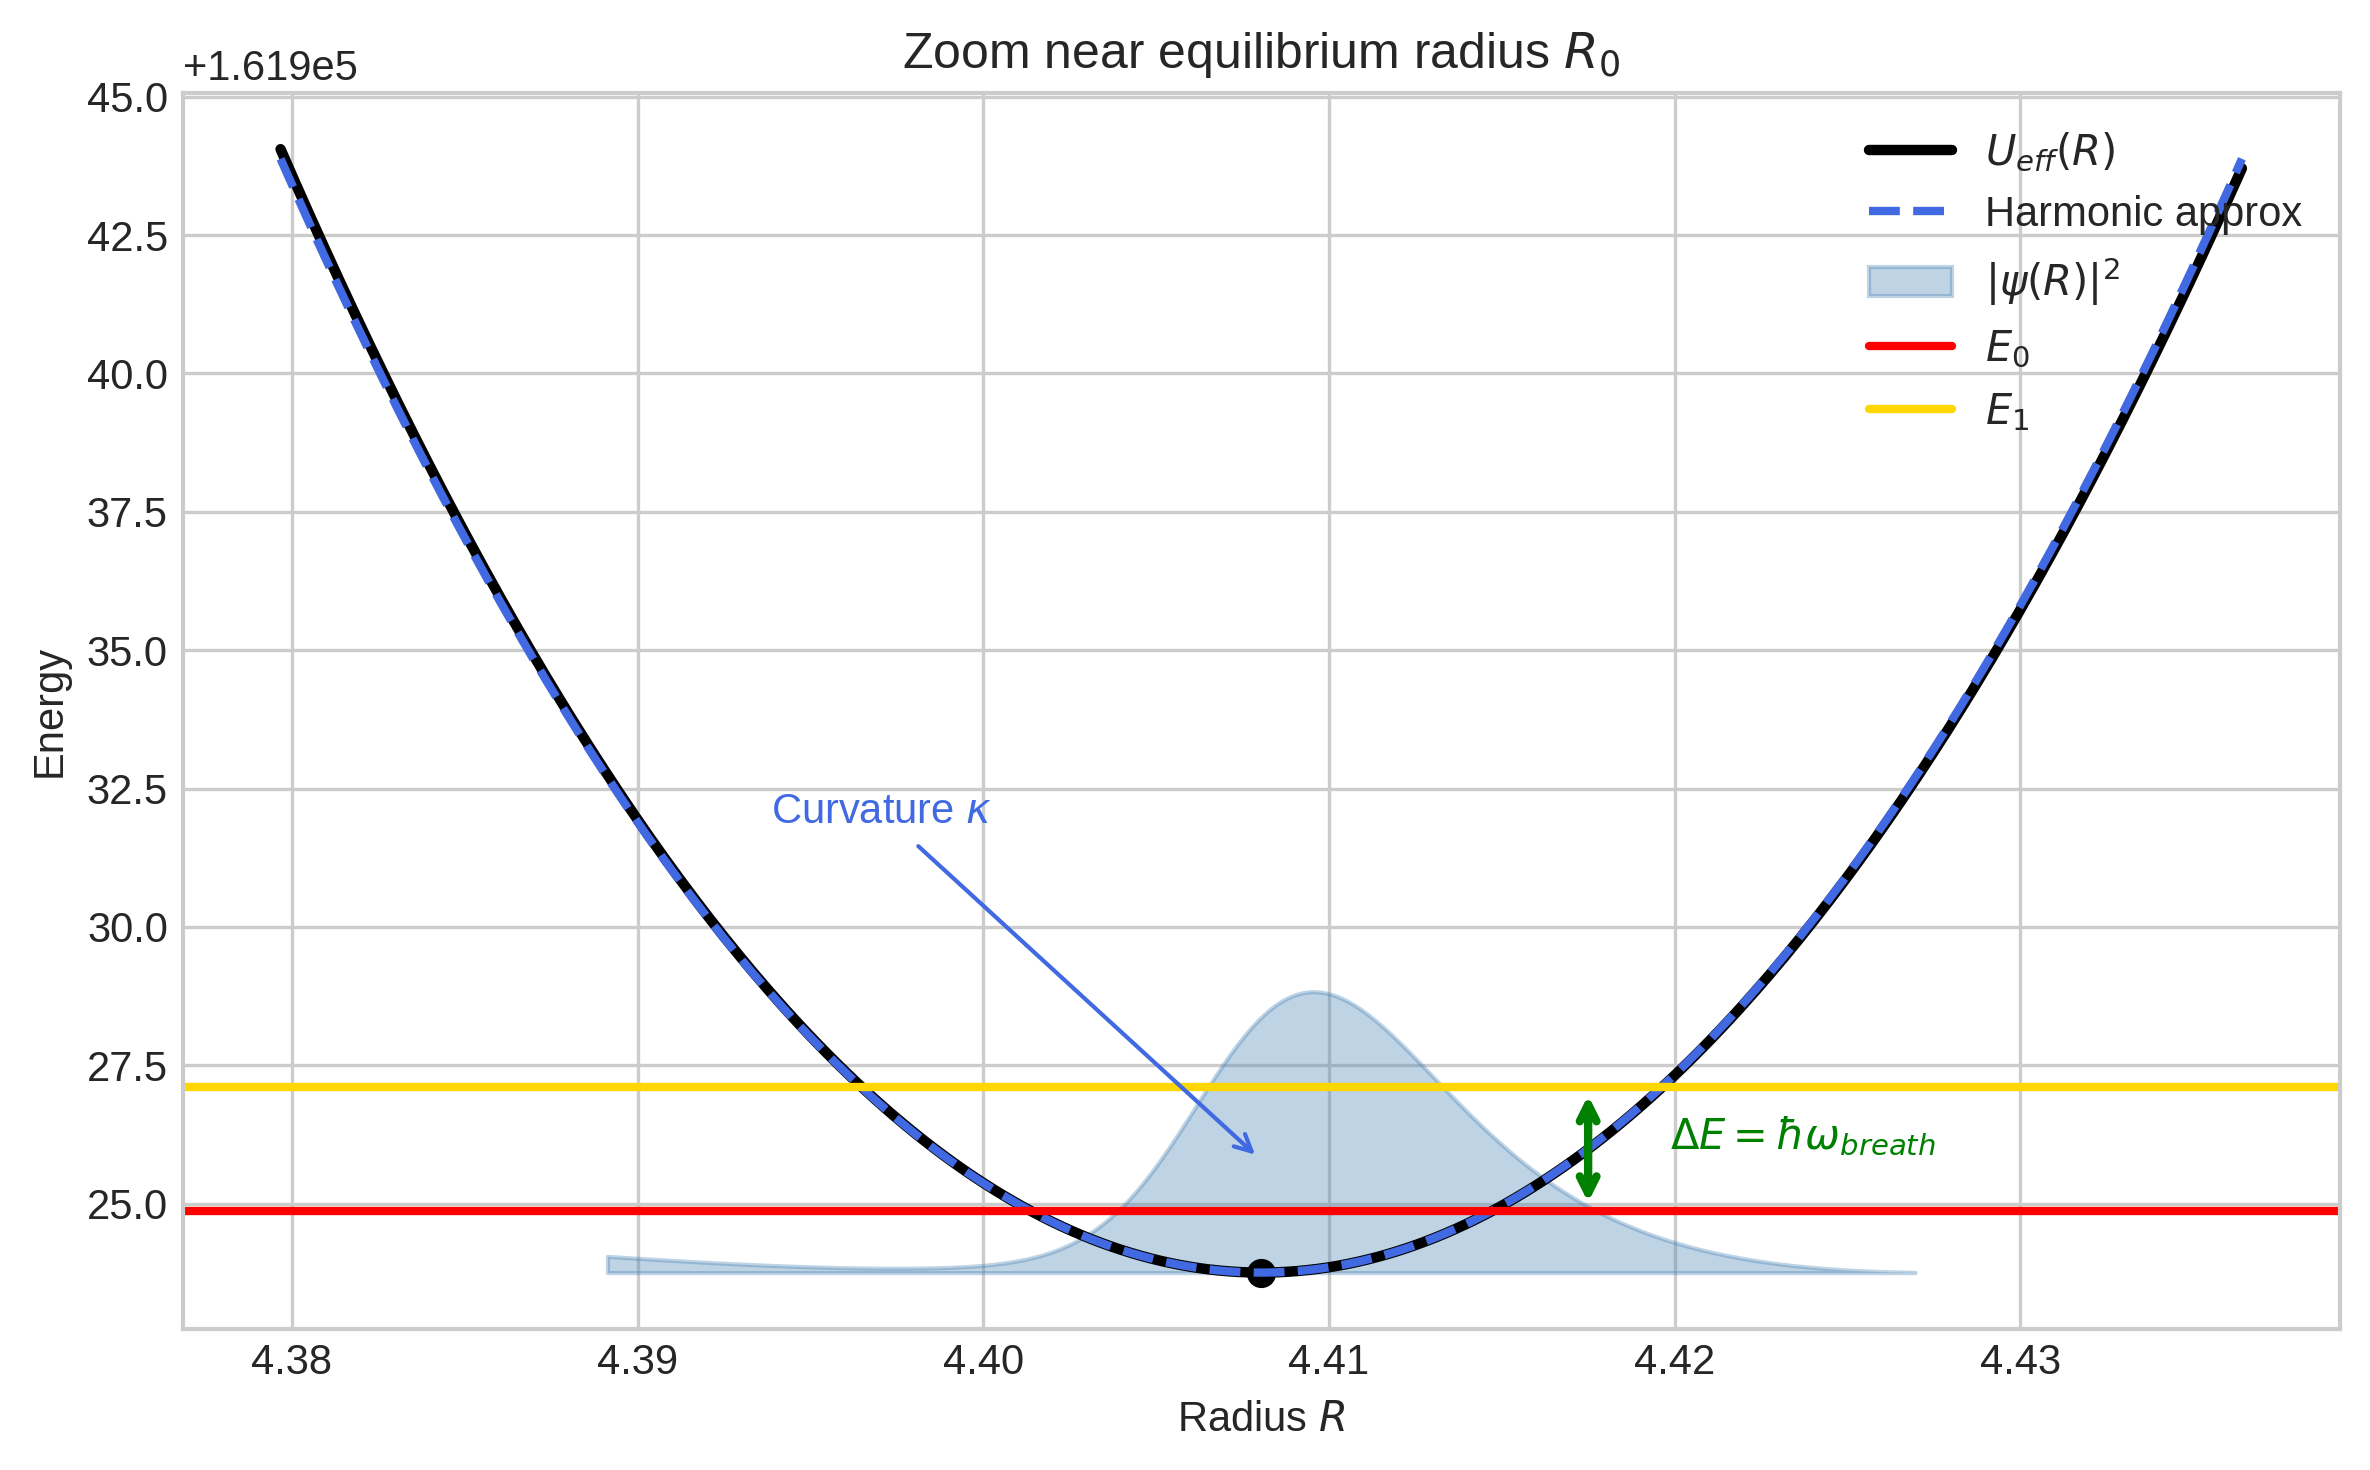

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)


class PhysicalSystem:

    def __init__(self,N=10000,omega_eff=1.0,g=1.0,m=1.0):

        self.N=N
        self.omega_eff=omega_eff
        self.g=g
        self.m=m
        self.hbar=1.0

        self.A=0.5*self.N*self.m*self.omega_eff**2
        self.B=(3*self.g/(8*np.pi))*(3/5)**(3/2)*self.N**2

        self.R0=((3*self.B)/(2*self.A))**(1/5)

        self.U0=self.A*self.R0**2+self.B/self.R0**3

        self.M_R=self.N*self.m
        self.kappa=5*self.N*self.m*self.omega_eff**2

        self.omega_breath=np.sqrt(5)*self.omega_eff

        self.sigma_R=np.sqrt(self.hbar/(2*self.M_R*self.omega_breath))

        self.E0=self.U0+0.5*self.hbar*self.omega_breath
        self.E1=self.U0+1.5*self.hbar*self.omega_breath
        self.dE=self.hbar*self.omega_breath



class WavefunctionNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.net=nn.Sequential(

            nn.Linear(1,32),
            nn.Tanh(),

            nn.Linear(32,32),
            nn.Tanh(),

            nn.Linear(32,1)

        )

    def forward(self,x):

        return self.net(x)


class Solver:

    def __init__(self,phys):

        self.phys=phys

        self.u=np.linspace(-4,4,300)
        self.du=self.u[1]-self.u[0]

        self.R=self.phys.R0+self.phys.sigma_R*self.u

        self.u_tensor=torch.tensor(self.u,dtype=torch.float32).reshape(-1,1)
        self.u_tensor.requires_grad_(True)

        self.model=WavefunctionNN()
        self.optimizer=optim.Adam(self.model.parameters(),lr=0.001)


    def compute_energy(self,psi):

        psi=psi.flatten()

        norm=torch.trapezoid(psi*psi,dx=self.du)

        psi=psi/torch.sqrt(norm)

        psi_u=torch.zeros_like(psi)
        psi_u[1:-1]=(psi[2:]-psi[:-2])/(2*self.du)

        psi_uu=torch.zeros_like(psi)
        psi_uu[1:-1]=(psi[2:]-2*psi[1:-1]+psi[:-2])/(self.du**2)

        T=-0.5*self.phys.hbar*self.phys.omega_breath*psi_uu*psi

        V=0.5*self.phys.kappa*self.phys.sigma_R**2*(self.u_tensor.flatten()**2)*psi*psi

        E=torch.trapezoid(T+V,dx=self.du)

        return self.phys.U0+E


    def train(self,epochs=3000):

        for e in range(epochs):

            self.optimizer.zero_grad()

            psi=self.model(self.u_tensor)

            E=self.compute_energy(psi)

            loss=(E-self.phys.E0)**2

            loss.backward()

            self.optimizer.step()

            if e%1000==0:

                print("Epoch",e,"Energy",E.item())

        with torch.no_grad():

            psi=self.model(self.u_tensor).flatten().numpy()

        norm=np.trapezoid(psi**2,dx=self.du)

        self.psi_final=psi/np.sqrt(norm)



    def plot_zoom_region(self):

        plt.style.use("seaborn-v0_8-whitegrid")

        fig,ax=plt.subplots(figsize=(8,5),dpi=300)

        R=np.linspace(self.phys.R0-6*self.phys.sigma_R,
                      self.phys.R0+6*self.phys.sigma_R,400)

        U=self.phys.A*R**2+self.phys.B/R**3

        ax.plot(R,U,color="black",lw=2.5,label=r"$U_{eff}(R)$")

        Uh=self.phys.U0+0.5*self.phys.kappa*(R-self.phys.R0)**2

        ax.plot(R,Uh,"--",color="royalblue",lw=2,label="Harmonic approx")


        prob=self.psi_final**2
        prob=prob/max(prob)

        scale=(max(U)-min(U))*0.25
        prob=prob*scale+self.phys.U0

        ax.fill_between(self.R,self.phys.U0,prob,
                        color="steelblue",alpha=0.35,
                        label=r"$|\psi(R)|^2$")


        ax.scatter(self.phys.R0,self.phys.U0,color="black")

        ax.axhline(self.phys.E0,color="red",lw=2,label=r"$E_0$")


        ax.axhline(self.phys.E1,color="gold",lw=2,label=r"$E_1$")


        ax.annotate("",
            xy=(self.phys.R0+2*self.phys.sigma_R,self.phys.E1),
            xytext=(self.phys.R0+2*self.phys.sigma_R,self.phys.E0),
            arrowprops=dict(arrowstyle="<->",color="green",lw=2))

        ax.text(self.phys.R0+2.5*self.phys.sigma_R,
                (self.phys.E0+self.phys.E1)/2,
                r"$\Delta E=\hbar\omega_{breath}$",
                color="green")


        ax.annotate(r"Curvature $\kappa$",
            xy=(self.phys.R0,self.phys.U0+0.1*(max(U)-self.phys.U0)),
            xytext=(self.phys.R0-3*self.phys.sigma_R,
                    self.phys.U0+0.4*(max(U)-self.phys.U0)),
            arrowprops=dict(arrowstyle="->",color="royalblue"),
            color="royalblue")

        ax.set_xlabel("Radius $R$")
        ax.set_ylabel("Energy")

        ax.set_title("Zoom near equilibrium radius $R_0$")

        ax.legend(loc="upper right")

        plt.tight_layout()
        plt.show()

def main():

    phys=PhysicalSystem(N=10000)

    solver=Solver(phys)

    solver.train()

    solver.plot_zoom_region()


if __name__=="__main__":

    main()